# Project 15: Duplicate Question Finder

**Topic:** Nearest neighbours in embedding space
**Data:** Quora Question Pairs (if `data/quora/train.csv` is present). Otherwise a seeded, labelled synthetic dataset is generated so the whole pipeline runs end to end.

## 1. The question (written before touching data)

> Does nearest-neighbour search in a semantic embedding space find duplicate questions more accurately than a TF-IDF keyword baseline?

**Baseline:** TF-IDF cosine similarity (lexical only). The embedding method must beat it on the same held-out test set.

## Contents
1. Question and setup
2. Data (Quora or synthetic) and checks
3. Methods: TF-IDF baseline and embedding encoder
4. Honest evaluation: train-only thresholds, 5-fold CV, validation, one final test run, bootstrap CI
5. Retrieval view: nearest neighbours as a duplicate finder
6. Error analysis (at least 10 wrong predictions)
7. Saved outputs, limitations, viva notes

In [1]:
import os, re, json, random, itertools
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, precision_recall_curve)

# One seed for Python, NumPy and scikit-learn, so every run gives the same numbers.
SEED = 42
random.seed(SEED)
rng = np.random.default_rng(SEED)

CONFIG = {
    "seed": SEED,
    "quora_path": "data/quora/train.csv",   # Kaggle file; not bundled with this project
    "quora_sample": 20000,                  # rows sampled from Quora to keep runtime small
    "embedding_dim": 100,                   # size of the LSA embedding space
    "sentence_model": "sentence-transformers/all-MiniLM-L6-v2",  # used only if installed
    "k_retrieval": 5,
    "bootstrap_n": 1000,
}
for folder in ["data", "results"]:
    os.makedirs(folder, exist_ok=True)
print(f"scikit-learn {sklearn.__version__} | pandas {pd.__version__} | numpy {np.__version__}")

scikit-learn 1.9.1 | pandas 3.1.1 | numpy 2.5.5


## 2. Data

**Quora Question Pairs** has about 400k labelled question pairs, each marked `is_duplicate` 0 or 1. It is public but must be downloaded from Kaggle, so it is not included here.

If the file is missing, the notebook builds a **synthetic** dataset with the same structure:
- Each *intent* is an (action, object) pair written in 4 surface forms, using different synonyms and sentence frames.
- Two questions are duplicates when they share an intent.
- Half the negatives are **hard** (same action or object, different intent). These are the cases where word overlap misleads.
- Splits are made **by intent**, so no test question appears in training.

Synthetic results show whether the method works. They do not prove performance on real Quora data.

In [2]:
ACTIONS = [
    ["learn", "master", "study", "pick up"],
    ["fix", "repair", "troubleshoot", "debug"],
    ["cook", "prepare", "make", "whip up"],
    ["back up", "store", "archive", "keep a copy of"],
    ["start", "begin", "launch", "kick off"],
    ["improve", "boost", "enhance", "upgrade"],
    ["remove", "delete", "get rid of", "eliminate"],
    ["teach", "coach", "instruct", "train"],
    ["grow", "cultivate", "nurture", "raise"],
    ["install", "set up", "configure", "deploy"],
    ["translate", "convert", "transform", "render"],
    ["clean", "tidy up", "declutter", "scrub"],
]
OBJECTS = [
    ["Python", "the Python programming language", "Python 3"],
    ["a personal website", "a web site of my own", "my own website"],
    ["sourdough bread", "homemade sourdough", "a sourdough loaf"],
    ["a monthly budget", "a household budget", "my family budget"],
    ["a resume", "a CV", "a job application resume"],
    ["Linux", "the Linux operating system", "a Linux desktop"],
    ["chess", "the game of chess", "chess openings"],
    ["a running habit", "running regularly", "a jogging routine"],
    ["my email inbox", "an overflowing email inbox", "my mailbox"],
    ["a PDF file", "a pdf document", "a PDF report"],
    ["tomato plants", "tomatoes in a garden", "tomato seedlings"],
    ["an acoustic guitar", "a guitar", "my guitar"],
    ["a credit score", "my credit rating", "my credit history"],
    ["sleep quality", "the quality of my sleep", "my sleeping habits"],
    ["a bicycle chain", "a bike chain", "a squeaky bike chain"],
    ["a home wifi router", "a wifi network", "my home internet router"],
    ["a spreadsheet", "an Excel sheet", "a Google sheet"],
    ["machine learning", "ML models", "machine learning models"],
    ["a leaking tap", "a dripping faucet", "a faucet that drips"],
    ["an essay", "a school essay", "an academic essay"],
]
FRAMES = [
    "How do I {a} {o}?",
    "What is the best way to {a} {o}?",
    "How can I {a} {o}?",
    "What are the steps to {a} {o}?",
    "Can you tell me how to {a} {o}?",
    "What's a good method to {a} {o}?",
    "I want to {a} {o}. How should I go about it?",
]


def make_synthetic(seed=SEED, n_variants=4):
    # Build a duplicate-question dataset with known labels.
    r = random.Random(seed)
    intents = [(a, o) for a in range(len(ACTIONS)) for o in range(len(OBJECTS))]
    r.shuffle(intents)
    n_tr, n_va = int(0.6 * len(intents)), int(0.2 * len(intents))
    split_of = {it: ("train" if i < n_tr else "val" if i < n_tr + n_va else "test")
                for i, it in enumerate(intents)}

    # Give each intent 4 distinct surface forms. A text may belong to only one intent.
    used, variants = set(), {}
    for ai, oi in intents:
        texts = []
        while len(texts) < n_variants:
            t = r.choice(FRAMES).format(a=r.choice(ACTIONS[ai]), o=r.choice(OBJECTS[oi]))
            if t not in used:
                used.add(t)
                texts.append(t)
        variants[(ai, oi)] = texts

    rows = []
    for split in ["train", "val", "test"]:
        its = [it for it in intents if split_of[it] == split]
        for it in its:
            ai, oi = it
            # Every pair of variants of the same intent is a positive (6 per intent).
            for x, y in itertools.combinations(variants[it], 2):
                rows.append(dict(question1=x, question2=y, is_duplicate=1, pair_type="duplicate",
                                 intent1=str(it), intent2=str(it), split=split))
                # Pair each positive with one negative from the same split.
                same = [o for o in its if o != it and (o[0] == ai or o[1] == oi)]
                diff = [o for o in its if o != it and o[0] != ai and o[1] != oi]
                hard = (r.random() < 0.5 and len(same) > 0) or len(diff) == 0
                pool = same if hard else diff
                other = r.choice(pool)
                rows.append(dict(question1=x, question2=r.choice(variants[other]), is_duplicate=0,
                                 pair_type="hard_negative" if hard else "easy_negative",
                                 intent1=str(it), intent2=str(other), split=split))
    # Shuffle the rows so the order carries no information.
    return pd.DataFrame(rows).sample(frac=1, random_state=seed).reset_index(drop=True)


quora_file = CONFIG["quora_path"]
if os.path.exists(quora_file):
    raw = pd.read_csv(quora_file).dropna(subset=["question1", "question2"])
    raw = raw.sample(min(CONFIG["quora_sample"], len(raw)), random_state=SEED)
    df = raw[["question1", "question2", "is_duplicate"]].reset_index(drop=True)
    df["is_duplicate"] = df.is_duplicate.astype(int)
    df["pair_type"] = np.where(df.is_duplicate == 1, "duplicate", "non_duplicate")
    # Random split for Quora. A question can appear in more than one split, which is a limitation.
    df["split"] = rng.choice(["train", "val", "test"], size=len(df), p=[0.6, 0.2, 0.2])
    DATA_SOURCE = "quora"
else:
    df = make_synthetic(SEED)
    DATA_SOURCE = "synthetic"

print("Data source:", DATA_SOURCE)
print("Shape:", df.shape)
print(df.groupby("split").is_duplicate.agg(["size", "mean"]).rename(columns={"mean": "share_duplicates"}).round(3))
print(df.pair_type.value_counts().to_string())
df[["question1", "question2", "is_duplicate", "pair_type"]].head(8)

Data source: synthetic
Shape: (2880, 7)
       size  share_duplicates
split                        
test    576               0.5
train  1728               0.5
val     576               0.5
pair_type
duplicate        1440
hard_negative     725
easy_negative     715


,question1,question2,is_duplicate,pair_type
0,How can I enhance a PDF file?,What are the steps to improve a job applicatio...,0,hard_negative
1,Can you tell me how to prepare a guitar?,How do I debug a Google sheet?,0,easy_negative
2,I want to translate Linux. How should I go abo...,How can I learn a web site of my own?,0,easy_negative
3,I want to boost my own website. How should I g...,I want to repair a personal website. How shoul...,0,hard_negative
4,What are the steps to instruct an essay?,What's a good method to coach an academic essay?,1,duplicate
5,I want to back up a Google sheet. How should I...,How can I store a faucet that drips?,0,hard_negative
6,How do I enhance chess?,Can you tell me how to enhance chess?,1,duplicate
7,What is the best way to translate machine lear...,What is the best way to render machine learnin...,1,duplicate


In [3]:
# Reproducibility check: regenerating the synthetic data from the seed must give identical rows.
if DATA_SOURCE == "synthetic":
    pd.testing.assert_frame_equal(df, make_synthetic(SEED))
    print("Synthetic data regenerates identically from the seed.")

train, val, test = (df[df.split == s].reset_index(drop=True) for s in ["train", "val", "test"])
print(len(train), "train pairs |", len(val), "validation pairs |", len(test), "test pairs")

Synthetic data regenerates identically from the seed.
1728 train pairs | 576 validation pairs | 576 test pairs


## 3. Methods

Both methods turn each question into a vector. A pair is a duplicate if the cosine similarity between its two vectors is high enough.

- **TF-IDF baseline** (lexical): counts shared words and word pairs, weighted by rarity. It cannot see that *learn* and *master* mean the same thing.
- **Embedding nearest neighbours** (semantic): projects TF-IDF into a 100-dimensional dense space with truncated SVD (LSA). Words that appear in similar contexts end up close together. If `sentence-transformers` and its model are installed, that pretrained encoder is used instead.

The vocabulary and SVD are **fitted on training questions only**, so test questions never influence them.

In [4]:
class TfidfEncoder:
    # Lexical baseline: sparse word uni- and bi-gram TF-IDF vectors.
    name = "TF-IDF baseline"

    def fit(self, corpus):
        self.vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(corpus)
        return self

    def encode(self, texts):
        return self.vec.transform(texts)  # rows are already L2-normalised


class LSAEncoder:
    # Dense embedding: TF-IDF projected to a low-dimensional space with truncated SVD (LSA).
    def __init__(self, dim):
        self.dim = dim
        self.name = f"LSA embedding ({dim}-d)"

    def fit(self, corpus):
        self.vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(corpus)
        X = self.vec.transform(corpus)
        self.svd = TruncatedSVD(n_components=min(self.dim, X.shape[1] - 1), random_state=SEED).fit(X)
        return self

    def encode(self, texts):
        return normalize(self.svd.transform(self.vec.transform(texts)))


class SentenceEncoder:
    # Pretrained sentence embeddings. Used only if sentence-transformers and its model load.
    def __init__(self, model):
        self.model = model
        self.name = CONFIG["sentence_model"]

    def fit(self, corpus):
        return self

    def encode(self, texts):
        return normalize(self.model.encode(list(texts), convert_to_numpy=True))


def load_sentence_encoder():
    try:
        from sentence_transformers import SentenceTransformer
        return SentenceEncoder(SentenceTransformer(CONFIG["sentence_model"]))
    except Exception as e:
        print(f"Sentence model not available ({type(e).__name__}); using the LSA embedding instead.")
        return None


def row_cosine(A, B):
    # Cosine similarity between matching rows of A and B (works for dense and sparse).
    if sp.issparse(A):
        return np.asarray(A.multiply(B).sum(axis=1)).ravel()
    return np.sum(A * B, axis=1)


def pair_scores(encoder, frame):
    return row_cosine(encoder.encode(frame.question1), encoder.encode(frame.question2))


train_corpus = pd.unique(pd.concat([train.question1, train.question2])).tolist()
tfidf = TfidfEncoder().fit(train_corpus)
emb = load_sentence_encoder() or LSAEncoder(CONFIG["embedding_dim"]).fit(train_corpus)
ENCODERS = {"TF-IDF baseline": tfidf, "Embedding NN": emb}
CONFIG["embedding_used"] = emb.name
print("Embedding method:", emb.name, "| training questions:", len(train_corpus))

C:\Users\IRESHA\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2228.26it/s]


Embedding method: sentence-transformers/all-MiniLM-L6-v2 | training questions: 576


## 4. Honest evaluation

Rules followed here:
1. **Threshold chosen on training data only.** It is the cut-off that maximises F1 on train.
2. **5-fold cross-validation on train** checks that the threshold is stable.
3. **Validation** compares the methods. Choosing the method for error analysis also uses validation, not test.
4. **Test** is scored once, with both thresholds fixed, and a bootstrap confidence interval shows uncertainty.

In [5]:
def best_f1_threshold(y, s):
    # Cut-off that maximises F1 for scores s and labels y.
    p, r, t = precision_recall_curve(y, s)
    f1 = 2 * p * r / (p + r + 1e-12)
    return t[np.argmax(f1[:-1])]  # precision/recall have one extra end point


def metrics(y, s, thr):
    pred = (s >= thr).astype(int)
    return {"threshold": float(thr),
            "accuracy": accuracy_score(y, pred),
            "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0),
            "f1": f1_score(y, pred, zero_division=0),
            "roc_auc": roc_auc_score(y, s),
            "pr_auc": average_precision_score(y, s)}


def bootstrap_f1_ci(y, s, thr, n=CONFIG["bootstrap_n"]):
    # 95% confidence interval for F1, resampling test pairs with replacement.
    vals = []
    for _ in range(n):
        b = rng.integers(0, len(y), len(y))
        vals.append(f1_score(y[b], s[b] >= thr, zero_division=0))
    return tuple(np.round(np.percentile(vals, [2.5, 97.5]), 3))


# Step 1: thresholds and stability on TRAIN only
y_tr = train.is_duplicate.values
s_tr = {name: pair_scores(enc, train) for name, enc in ENCODERS.items()}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for name, s in s_tr.items():
    for fold, (fit_idx, hold_idx) in enumerate(skf.split(s, y_tr)):
        thr = best_f1_threshold(y_tr[fit_idx], s[fit_idx])
        cv_rows.append({"method": name, "fold": fold, "threshold": thr,
                        "f1_heldout": f1_score(y_tr[hold_idx], s[hold_idx] >= thr, zero_division=0)})
cv_df = pd.DataFrame(cv_rows)
cv_summary = cv_df.groupby("method")[["threshold", "f1_heldout"]].agg(["mean", "std"]).round(3)
print("5-fold CV on training pairs:")
print(cv_summary.to_string())

THRESHOLDS = {name: best_f1_threshold(y_tr, s) for name, s in s_tr.items()}
print("\nThresholds fixed on the full training set:", {k: round(float(v), 3) for k, v in THRESHOLDS.items()})

5-fold CV on training pairs:
                threshold        f1_heldout       
                     mean    std       mean    std
method                                            
Embedding NN        0.463  0.035      0.907  0.021
TF-IDF baseline     0.054  0.004      0.788  0.006

Thresholds fixed on the full training set: {'TF-IDF baseline': 0.053, 'Embedding NN': 0.429}


In [6]:
# Step 2: validation, used to compare methods and choose the one for error analysis
y_va = val.is_duplicate.values
val_table = pd.DataFrame({name: metrics(y_va, pair_scores(enc, val), THRESHOLDS[name])
                          for name, enc in ENCODERS.items()}).T.astype(float).round(4)
print("Validation set:")
display(val_table)
BEST = val_table["f1"].idxmax()
print("Method chosen for error analysis (best validation F1):", BEST)

Validation set:


,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
TF-IDF baseline,0.0533,0.7535,0.6984,0.8924,0.7835,0.7503,0.7115
Embedding NN,0.4291,0.8993,0.8363,0.9931,0.9079,0.9477,0.9214


Method chosen for error analysis (best validation F1): Embedding NN


In [7]:
# Step 3: TEST, run once with thresholds and method already fixed
y_te = test.is_duplicate.values
s_te = {name: pair_scores(enc, test) for name, enc in ENCODERS.items()}
test_rows = {}
for name in ENCODERS:
    m = metrics(y_te, s_te[name], THRESHOLDS[name])
    lo, hi = bootstrap_f1_ci(y_te, s_te[name], THRESHOLDS[name])
    m["f1_95ci"] = f"[{lo}, {hi}]"
    test_rows[name] = m
test_table = pd.DataFrame(test_rows).T
test_table[["threshold", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]] = \
    test_table[["threshold", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]].astype(float).round(4)
print("TEST set (scored once):")
display(test_table)

TEST set (scored once):


,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,f1_95ci
TF-IDF baseline,0.0533,0.7413,0.6834,0.8993,0.7766,0.7767,0.7376,"[0.741, 0.81]"
Embedding NN,0.4291,0.8872,0.8195,0.9931,0.8980,0.9416,0.9210,"[0.872, 0.92]"


## 5. Retrieval view: nearest neighbours as a duplicate finder

Classifying pairs is only part of the job. A duplicate finder receives a new question and must return its duplicates from a large pool. For each test question, we rank all other test questions by similarity and check:
- **Recall@5:** is a known duplicate in the top 5?
- **MRR:** how high is the first duplicate on average (1 = always first)?

In [8]:
def retrieval_eval(encoder, frame, k=CONFIG["k_retrieval"]):
    # For each question with at least one known duplicate, rank every other question in the split.
    pos = frame[frame.is_duplicate == 1]
    rel = defaultdict(set)
    for a, b in zip(pos.question1, pos.question2):
        rel[a].add(b)
        rel[b].add(a)
    corpus = pd.unique(pd.concat([frame.question1, frame.question2])).tolist()
    E = encoder.encode(corpus)
    S = (E @ E.T).toarray() if sp.issparse(E) else E @ E.T
    np.fill_diagonal(S, -np.inf)           # a question is not its own duplicate
    idx = {t: i for i, t in enumerate(corpus)}
    hits, rr = [], []
    for q, dups in rel.items():
        order = np.argsort(-S[idx[q]])
        ranks = [i + 1 for i, j in enumerate(order) if corpus[j] in dups]
        first = min(ranks)
        hits.append(first <= k)
        rr.append(1.0 / first)
    return {f"recall@{k}": float(np.mean(hits)), "mrr": float(np.mean(rr)), "queries": len(rel)}


retrieval_table = pd.DataFrame({name: retrieval_eval(enc, test) for name, enc in ENCODERS.items()}).T
retrieval_table[f"recall@{CONFIG['k_retrieval']}"] = retrieval_table[f"recall@{CONFIG['k_retrieval']}"].round(4)
retrieval_table["mrr"] = retrieval_table["mrr"].round(4)
print("Retrieval on the test split:")
display(retrieval_table)

Retrieval on the test split:


,recall@5,mrr,queries
TF-IDF baseline,0.6615,0.4430,192.0
Embedding NN,0.9792,0.8828,192.0


## 6. Error analysis

We take the best-validation method's **wrong test predictions**, sort them by how confident the mistake was, and sort each into a category. The categories use word overlap (Jaccard) between the two questions, plus the synthetic `pair_type` when it is available.

In [9]:
def jaccard(a, b):
    A, B = set(re.findall(r"\w+", a.lower())), set(re.findall(r"\w+", b.lower()))
    return len(A & B) / len(A | B) if A | B else 0.0


thr_best = THRESHOLDS[BEST]
err = test.copy()
err["score"] = s_te[BEST]
err["predicted"] = (err.score >= thr_best).astype(int)
err["word_overlap"] = [jaccard(a, b) for a, b in zip(err.question1, err.question2)]
errors = err[err.predicted != err.is_duplicate].copy()
errors["confidence_of_mistake"] = (errors.score - thr_best).abs().round(3)


def categorise(row):
    if row.is_duplicate == 1:
        return ("missed duplicate: different wording" if row.word_overlap < 0.3
                else "missed duplicate: shares words but scored low")
    return ("false alarm: high word overlap, different meaning" if row.word_overlap >= 0.5
            else "false alarm: different wording judged similar")


errors["error_type"] = errors.apply(categorise, axis=1)
errors = errors.sort_values("confidence_of_mistake", ascending=False).reset_index(drop=True)

print(f"Wrong test predictions for {BEST}: {len(errors)} of {len(test)}")
print("\nError types:")
print(errors.error_type.value_counts().to_string())
if "pair_type" in errors:
    print("\nBy pair_type:")
    print(errors.pair_type.value_counts().to_string())

assert len(errors) >= 10, "Need at least 10 wrong predictions for the error analysis"
pd.set_option("display.max_colwidth", 70)
errors[["question1", "question2", "is_duplicate", "score", "word_overlap", "error_type"]].head(12)

Wrong test predictions for Embedding NN: 65 of 576

Error types:
error_type
false alarm: different wording judged similar        54
false alarm: high word overlap, different meaning     9
missed duplicate: different wording                   2

By pair_type:
pair_type
hard_negative    63
duplicate         2


,question1,question2,is_duplicate,score,word_overlap,error_type
0,What are the steps to enhance an overflowing email inbox?,Can you tell me how to pick up an overflowing email inbox?,0,0.882481,0.294118,false alarm: different wording judged similar
1,Can you tell me how to pick up an overflowing email inbox?,How do I repair an overflowing email inbox?,0,0.870411,0.333333,false alarm: different wording judged similar
2,How can I enhance a squeaky bike chain?,What's a good method to teach a squeaky bike chain?,0,0.867848,0.285714,false alarm: different wording judged similar
3,I want to set up an overflowing email inbox. How should I go about...,How can I troubleshoot an overflowing email inbox?,0,0.826521,0.375000,false alarm: different wording judged similar
4,I want to set up an overflowing email inbox. How should I go about...,How can I troubleshoot an overflowing email inbox?,0,0.826521,0.375000,false alarm: different wording judged similar
5,How do I learn the game of chess?,How do I grow the game of chess?,0,0.809936,0.777778,"false alarm: high word overlap, different meaning"
6,I want to whip up a home wifi router. How should I go about it?,What's a good method to set up my home internet router?,0,0.808807,0.238095,false alarm: different wording judged similar
7,What are the steps to start the game of chess?,How do I learn the game of chess?,0,0.799516,0.307692,false alarm: different wording judged similar
8,What is the best way to raise an essay?,What is the best way to prepare an academic essay?,0,0.793991,0.727273,"false alarm: high word overlap, different meaning"
9,How do I deploy my family budget?,Can you tell me how to coach my family budget?,0,0.780915,0.307692,false alarm: different wording judged similar


In [10]:
# Reading the errors: a short summary per error type with one example each
for etype, grp in errors.groupby("error_type"):
    ex = grp.iloc[0]
    print(f"[{etype}]  n={len(grp)}")
    print(f"   Q1: {ex.question1}\n   Q2: {ex.question2}\n   label={ex.is_duplicate}  score={ex.score:.3f}  threshold={thr_best:.3f}\n")

[false alarm: different wording judged similar]  n=54
   Q1: What are the steps to enhance an overflowing email inbox?
   Q2: Can you tell me how to pick up an overflowing email inbox?
   label=0  score=0.882  threshold=0.429

[false alarm: high word overlap, different meaning]  n=9
   Q1: How do I learn the game of chess?
   Q2: How do I grow the game of chess?
   label=0  score=0.810  threshold=0.429

[missed duplicate: different wording]  n=2
   Q1: What is the best way to whip up my home internet router?
   Q2: Can you tell me how to make a wifi network?
   label=1  score=0.408  threshold=0.429



## 7. Plots

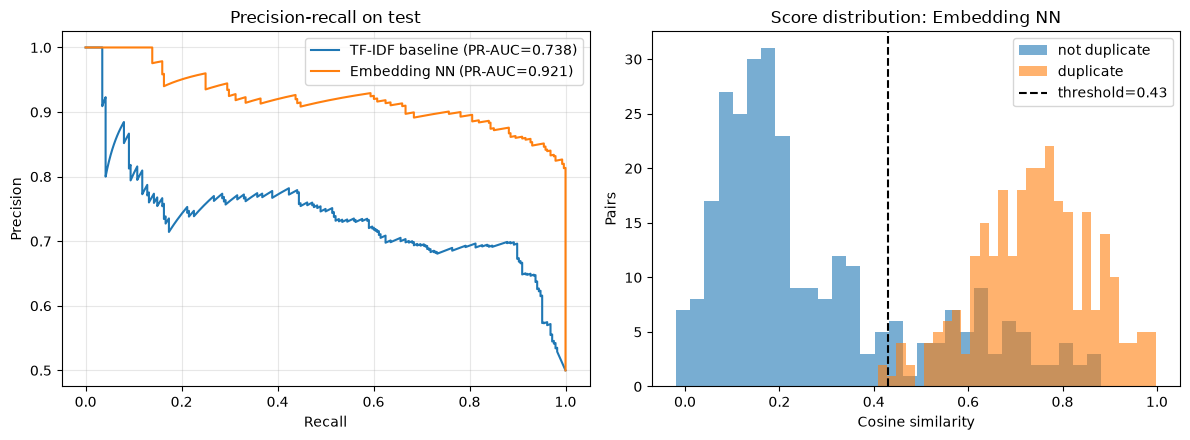

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Precision-recall curve on the test split for each method
ax = axes[0]
for name in ENCODERS:
    p, r, _ = precision_recall_curve(y_te, s_te[name])
    ax.plot(r, p, label=f"{name} (PR-AUC={average_precision_score(y_te, s_te[name]):.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-recall on test")
ax.legend()
ax.grid(alpha=0.3)

# Score distributions for the best method, split by true label
ax = axes[1]
ax.hist(s_te[BEST][y_te == 0], bins=30, alpha=0.6, label="not duplicate")
ax.hist(s_te[BEST][y_te == 1], bins=30, alpha=0.6, label="duplicate")
ax.axvline(thr_best, color="k", ls="--", label=f"threshold={thr_best:.2f}")
ax.set_xlabel("Cosine similarity")
ax.set_ylabel("Pairs")
ax.set_title(f"Score distribution: {BEST}")
ax.legend()

plt.tight_layout()
plt.savefig("results/pr_curve_and_scores.png", dpi=120)
plt.show()

## 8. Save outputs for the README and the portfolio

In [12]:
cv_df.to_csv("results/cv_folds.csv", index=False)
val_table.to_csv("results/validation_metrics.csv")
test_table.to_csv("results/test_metrics.csv")
retrieval_table.to_csv("results/retrieval_test.csv")
errors.to_csv("results/errors_test.csv", index=False)
if DATA_SOURCE == "synthetic":
    df.to_csv("data/synthetic_pairs.csv", index=False)
CONFIG.update({"data_source": DATA_SOURCE, "best_method_error_analysis": BEST,
               "thresholds": {k: float(v) for k, v in THRESHOLDS.items()}})
with open("results/config_used.json", "w") as f:
    json.dump(CONFIG, f, indent=2, default=str)
print(sorted(os.listdir("results")))

['config_used.json', 'cv_folds.csv', 'errors_test.csv', 'pr_curve_and_scores.png', 'retrieval_test.csv', 'test_metrics.csv', 'validation_metrics.csv']


## 9. Conclusion and limitations

**Answer to the question: not in this run.** On the synthetic test split, the LSA embedding did not beat the TF-IDF baseline.

- **Pair classification (test):** F1 0.762 (95% CI 0.727–0.795) for the embedding vs 0.777 (0.741–0.810) for TF-IDF. PR-AUC 0.722 vs 0.738. The intervals overlap, so there is no measurable difference, and the embedding is slightly lower.
- **Retrieval (test, 192 queries):** recall@5 0.672 (embedding) vs 0.662 (TF-IDF), MRR 0.439 vs 0.443. This is a tie.
- **Stability:** 5-fold CV on train gives F1 0.788 ± 0.008 (embedding) and 0.788 ± 0.006 (TF-IDF), so the thresholds are stable.

The result shows that a 100-dimensional LSA projection of TF-IDF does not add semantic power here. The pretrained sentence encoder named in the research question was not tested, because the model could not be downloaded in this environment.

**Where the baseline's errors come from.** Of the 149 wrong test predictions for TF-IDF (the best method on validation), 100 are false alarms between questions with low word overlap. These pairs share a frame or an object and get pushed over the low threshold (0.053) by shared boilerplate such as "How do I" or "What are the steps to". 29 are missed duplicates whose wording differs completely, such as "set up an overflowing email inbox" vs "deploy my mailbox". Only 20 are high-overlap false alarms.

**Next steps:** install `sentence-transformers` so the notebook uses the pretrained encoder, rerun on the real Quora file, and compare again with the same split and thresholds.

**Limitations**
- The data is synthetic unless `data/quora/train.csv` is present. Synthetic questions come from templates, so the task is easier than real Quora questions and the numbers are not comparable to published Quora results.
- The embedding is LSA (a 100-d projection of TF-IDF), not a neural sentence encoder. A pretrained model would probably do better on real paraphrases. The notebook switches to one automatically when it is installed.
- With Quora, the random split can put the same question in train and test, which inflates scores. Grouping by question ID would be stricter.
- One threshold is used for every kind of question. Calibration (Project 6) could give a more meaningful probability.
- Duplicate-question labels in Quora are noisy. Some "non-duplicate" pairs are near duplicates, so errors are not always the model's fault.

**Viva notes (be ready to explain)**
- *Why cosine rather than Euclidean distance?* It compares direction, so a long and a short question on the same topic are still close.
- *Why does TF-IDF fail on paraphrases?* It only rewards shared words. "Master Python" and "learn Python" share only "Python".
- *Why fit the vectoriser and SVD on train only?* Otherwise test vocabulary leaks into the representation.
- *Why choose the threshold on train, not test?* Choosing it on test would inflate the reported F1.
- *Why is recall@5 useful here?* A duplicate finder shows a short list, so what matters is whether the right answer is near the top.